# Preparação dos dados para o RAG

## Objetivo
Ler os CSVs originais (`data/raw`), corrigir problemas de formato, padronizar nomes e tipos e gerar:
- `data/processed/*.csv`: uma tabela por arquivo, **1ª coluna = chave única** (o `ingest.py` usa essa convenção para o ID de cada documento);
- `data/quality/qualidade_dados.csv`: relatório dos problemas encontrados e de como foram tratados. Ele também é indexado, então o RAG consegue responder "os dados estão limpos?".

Os dados originais não são alterados, e nenhum valor desconhecido é preenchido com valores inventados.

> **Dados de exemplo:** Northwind, banco de exemplo da Microsoft (licença MIT), em CSV pelo repositório `neo4j-contrib/northwind-neo4j`.
> **ADAPTE:** para usar outra base, troque este notebook mantendo as duas saídas acima.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')
QUALITY = Path('../data/quality')

pd.options.display.max_columns = None

## 1. Leitura robusta

Alguns arquivos têm vírgulas **sem aspas** dentro de campos de texto (`24, place Kléber`, `Pavlova, Ltd.`). O `pd.read_csv` falha nessas linhas (`Expected 11 fields, saw 12`).

Em todos os casos, a vírgula intrusa vem seguida de espaço. A regra de reparo é: **numa linha com campos a mais, um campo que começa com espaço é continuação do anterior.** Linhas com o número certo de campos não são tocadas, e o `assert` garante que toda linha reparada fica com o número de colunas do cabeçalho.

In [2]:
def ler_csv(nome):
    """Lê um CSV de data/raw reparando vírgulas sem aspas. Retorna (DataFrame, nº de linhas reparadas)."""
    with open(RAW / f'{nome}.csv', encoding='utf-8') as arquivo:
        linhas = list(csv.reader(arquivo))
    cabecalho, registros, reparadas = linhas[0], [], 0
    for linha in linhas[1:]:
        if len(linha) != len(cabecalho):
            campos = []
            for valor in linha:
                if campos and valor.startswith(' '):
                    campos[-1] += ',' + valor  # continuação do campo anterior
                else:
                    campos.append(valor)
            assert len(campos) == len(cabecalho), f'{nome}: linha não reparável: {linha[:3]}'
            linha, reparadas = campos, reparadas + 1
        registros.append(linha)
    return pd.DataFrame(registros, columns=cabecalho), reparadas


ARQUIVOS = ['categories', 'customers', 'employees', 'orders', 'order-details', 'products', 'shippers', 'suppliers']
raw, reparos = {}, {}
for nome in ARQUIVOS:
    raw[nome], reparos[nome] = ler_csv(nome)

pd.DataFrame({'registros': {n: len(df) for n, df in raw.items()}, 'linhas_reparadas': reparos})

,registros,linhas_reparadas
categories,8,0
customers,91,24
employees,9,0
orders,830,176
order-details,2155,0
products,77,0
shippers,3,0
suppliers,29,9


In [3]:
# Conferência visual de algumas linhas reparadas
raw['customers'][raw['customers']['address'].str.contains(', ', regex=False)][['customerID', 'companyName', 'address', 'city']].head()

,customerID,companyName,address,city
6,BLONP,Blondesddsl père et fils,"24, place Kléber",Strasbourg
7,BOLID,Bólido Comidas preparadas,"C/ Araquil, 67",Madrid
8,BONAP,Bon app',"12, rue des Bouchers",Marseille
14,COMMI,Comércio Mineiro,"Av. dos Lusíadas, 23",Sao Paulo
17,DUMON,Du monde entier,"67, rue des Cinquante Otages",Nantes


### Valores ausentes
O marcador literal `NULL` (texto) representa ausência. Ele vira `NaN` para que `isna()` o detecte e para que o `ingest.py` pule o campo no documento (campo nulo só gera ruído no embedding).

In [4]:
n_null = sum(int((df == 'NULL').sum().sum()) for df in raw.values())
raw = {nome: df.replace({'NULL': np.nan, '': np.nan}) for nome, df in raw.items()}
print('Células com NULL convertidas em NaN:', n_null)
pd.DataFrame({nome: df.isna().sum() for nome, df in raw.items()}).fillna(0).astype(int).loc[lambda x: x.sum(axis=1) > 0]

Células com NULL convertidas em NaN: 695


,categories,customers,employees,orders,order-details,products,shippers,suppliers
fax,0,22,0,0,0,0,0,16
homePage,0,0,0,0,0,0,0,24
postalCode,0,1,0,0,0,0,0,0
region,0,60,4,0,0,0,0,20
reportsTo,0,0,1,0,0,0,0,0
shipPostalCode,0,0,0,19,0,0,0,0
shipRegion,0,0,0,507,0,0,0,0
shippedDate,0,0,0,21,0,0,0,0


## 2. Colunas: nomes, tipos e remoção de binários

- Nomes em `snake_case` português, mesmo idioma das perguntas. Os **valores** continuam em inglês, como na fonte.
- `picture`, `photo` e `photoPath` são imagens em hexadecimal: não têm valor para busca textual e incham os documentos.
- Datas no formato `AAAA-MM-DD`.

In [5]:
categorias = raw['categories'].drop(columns='picture').rename(columns={
    'categoryID': 'id_categoria', 'categoryName': 'categoria', 'description': 'descricao'})

clientes = raw['customers'].rename(columns={
    'customerID': 'id_cliente', 'companyName': 'empresa', 'contactName': 'contato', 'contactTitle': 'cargo_contato',
    'address': 'endereco', 'city': 'cidade', 'region': 'regiao', 'postalCode': 'cep', 'country': 'pais',
    'phone': 'telefone', 'fax': 'fax'})

fornecedores = raw['suppliers'].rename(columns={
    'supplierID': 'id_fornecedor', 'companyName': 'empresa', 'contactName': 'contato', 'contactTitle': 'cargo_contato',
    'address': 'endereco', 'city': 'cidade', 'region': 'regiao', 'postalCode': 'cep', 'country': 'pais',
    'phone': 'telefone', 'fax': 'fax', 'homePage': 'site'})

transportadoras = raw['shippers'].rename(columns={
    'shipperID': 'id_transportadora', 'companyName': 'empresa', 'phone': 'telefone'})

In [6]:
funcionarios = raw['employees'].drop(columns=['photo', 'photoPath']).rename(columns={
    'employeeID': 'id_funcionario', 'title': 'cargo', 'titleOfCourtesy': 'tratamento',
    'birthDate': 'data_nascimento', 'hireDate': 'data_admissao', 'address': 'endereco', 'city': 'cidade',
    'region': 'regiao', 'postalCode': 'cep', 'country': 'pais', 'homePhone': 'telefone', 'extension': 'ramal',
    'notes': 'observacoes', 'reportsTo': 'id_supervisor'})
# Nome completo numa coluna só: é como o usuário pergunta ("Nancy Davolio")
funcionarios.insert(1, 'nome', funcionarios.pop('firstName') + ' ' + funcionarios.pop('lastName'))
for col in ['data_nascimento', 'data_admissao']:
    funcionarios[col] = pd.to_datetime(funcionarios[col]).dt.strftime('%Y-%m-%d')
funcionarios[['id_funcionario', 'nome', 'cargo', 'data_admissao', 'id_supervisor']]

,id_funcionario,nome,cargo,data_admissao,id_supervisor
0,1,Nancy Davolio,Sales Representative,1992-05-01,2
1,2,Andrew Fuller,"Vice President, Sales",1992-08-14,NaN
2,3,Janet Leverling,Sales Representative,1992-04-01,2
3,4,Margaret Peacock,Sales Representative,1993-05-03,2
4,5,Steven Buchanan,Sales Manager,1993-10-17,2
5,6,Michael Suyama,Sales Representative,1993-10-17,5
6,7,Robert King,Sales Representative,1994-01-02,5
7,8,Laura Callahan,Inside Sales Coordinator,1994-03-05,2
8,9,Anne Dodsworth,Sales Representative,1994-11-15,5


In [7]:
produtos = raw['products'].rename(columns={
    'productID': 'id_produto', 'productName': 'produto', 'supplierID': 'id_fornecedor', 'categoryID': 'id_categoria',
    'quantityPerUnit': 'qtd_por_unidade', 'unitPrice': 'preco_unitario', 'unitsInStock': 'estoque',
    'unitsOnOrder': 'em_pedido', 'reorderLevel': 'nivel_reposicao', 'discontinued': 'descontinuado'})
for col in ['preco_unitario', 'estoque', 'em_pedido', 'nivel_reposicao']:
    produtos[col] = pd.to_numeric(produtos[col])
produtos['descontinuado'] = produtos['descontinuado'] == '1'

itens_pedido = raw['order-details'].rename(columns={
    'orderID': 'id_pedido', 'productID': 'id_produto', 'unitPrice': 'preco_unitario',
    'quantity': 'quantidade', 'discount': 'desconto'})
for col in ['preco_unitario', 'quantidade', 'desconto']:
    itens_pedido[col] = pd.to_numeric(itens_pedido[col])

pedidos = raw['orders'].rename(columns={
    'orderID': 'id_pedido', 'customerID': 'id_cliente', 'employeeID': 'id_funcionario', 'orderDate': 'data_pedido',
    'requiredDate': 'data_prevista', 'shippedDate': 'data_envio', 'shipVia': 'id_transportadora', 'freight': 'frete',
    'shipName': 'destinatario', 'shipAddress': 'endereco_entrega', 'shipCity': 'cidade_entrega',
    'shipRegion': 'regiao_entrega', 'shipPostalCode': 'cep_entrega', 'shipCountry': 'pais_entrega'})
for col in ['data_pedido', 'data_prevista', 'data_envio']:
    pedidos[col] = pd.to_datetime(pedidos[col]).dt.strftime('%Y-%m-%d')  # NaT continua NaN
pedidos['frete'] = pd.to_numeric(pedidos['frete'])

In [8]:
# Chaves únicas: requisito do ingest.py (1ª coluna de cada tabela indexada)
for nome, df in {'categorias': categorias, 'clientes': clientes, 'fornecedores': fornecedores,
                 'transportadoras': transportadoras, 'funcionarios': funcionarios, 'produtos': produtos,
                 'pedidos': pedidos}.items():
    assert df.iloc[:, 0].is_unique, nome
assert not itens_pedido.duplicated(['id_pedido', 'id_produto']).any()  # chave composta: não é indexada
print('Chaves únicas ok')

Chaves únicas ok


## 3. Regras de negócio

### Valor do item e do pedido
**Valor líquido do item = preço praticado × quantidade × (1 − desconto).** O frete fica de fora (é custo de entrega, não venda de produto).

O preço do item (`order-details`) é o praticado na venda e pode diferir do preço de tabela atual (`products`). Para faturamento vale o preço do item.

In [9]:
itens_pedido['valor'] = itens_pedido['preco_unitario'] * itens_pedido['quantidade'] * (1 - itens_pedido['desconto'])

comparacao_preco = itens_pedido.merge(produtos[['id_produto', 'preco_unitario']], on='id_produto', suffixes=('', '_tabela'))
n_preco_diferente = int((comparacao_preco['preco_unitario'] != comparacao_preco['preco_unitario_tabela']).sum())
print(f'Itens com preço diferente do preço de tabela: {n_preco_diferente} de {len(itens_pedido)}')

totais = itens_pedido.groupby('id_pedido').agg(valor_total=('valor', 'sum'), n_itens=('id_produto', 'count'))
pedidos = pedidos.merge(totais.round({'valor_total': 2}), on='id_pedido', how='left')
pedidos[['id_pedido', 'data_pedido', 'valor_total', 'n_itens']].head()

Itens com preço diferente do preço de tabela: 658 de 2155


,id_pedido,data_pedido,valor_total,n_itens
0,10248,1996-07-04,440.00,3
1,10249,1996-07-05,1863.40,2
2,10250,1996-07-08,1552.60,3
3,10251,1996-07-08,654.06,3
4,10252,1996-07-09,3597.90,3


### Situação dos pedidos
- `enviado`: há data de envio. Pedidos não enviados continuam na base e no faturamento (o pedido existe), mas ficam sinalizados.
- `atrasado`: enviado depois da data prevista.
- `ano_mes`: usado pelas tools para agregações por ano e para detectar anos parciais.

In [10]:
pedidos['ano_mes'] = pedidos['data_pedido'].str[:7]
pedidos['enviado'] = pedidos['data_envio'].notna()
pedidos['atrasado'] = pedidos['enviado'] & (pedidos['data_envio'] > pedidos['data_prevista'])
print('Não enviados:', (~pedidos['enviado']).sum(), '| Atrasados:', pedidos['atrasado'].sum())

Não enviados: 21 | Atrasados: 37


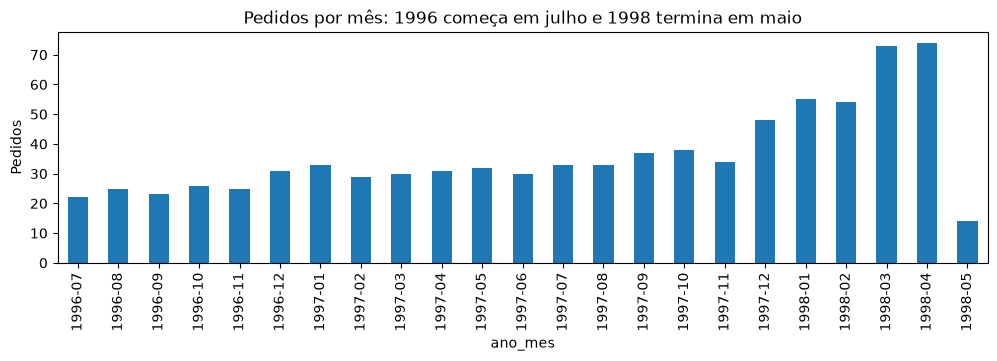

ano_mes
1996     6
1997    12
1998     5
dtype: int64

In [11]:
por_mes = pedidos.groupby('ano_mes').size()
por_mes.plot.bar(figsize=(12, 3))
plt.title('Pedidos por mês: 1996 começa em julho e 1998 termina em maio')
plt.ylabel('Pedidos')
plt.show()

meses_por_ano = por_mes.groupby(por_mes.index.str[:4]).size()
anos_parciais = meses_por_ano[meses_por_ano < 12]
meses_por_ano

### Estoque
- `sem_estoque`: estoque zerado.
- `precisa_repor`: produto ativo cujo estoque + unidades já em pedido não supera o nível de reposição.

In [12]:
produtos['sem_estoque'] = produtos['estoque'] == 0
produtos['precisa_repor'] = (~produtos['descontinuado']
                             & (produtos['estoque'] + produtos['em_pedido'] <= produtos['nivel_reposicao']))
produtos[produtos['sem_estoque'] | produtos['precisa_repor']][
    ['id_produto', 'produto', 'estoque', 'em_pedido', 'nivel_reposicao', 'descontinuado', 'sem_estoque', 'precisa_repor']]

,id_produto,produto,estoque,em_pedido,nivel_reposicao,descontinuado,sem_estoque,precisa_repor
4,5,Chef Anton's Gumbo Mix,0,0,0,True,True,False
16,17,Alice Mutton,0,0,0,True,True,False
28,29,Thüringer Rostbratwurst,0,0,0,True,True,False
29,30,Nord-Ost Matjeshering,10,0,15,False,False,True
30,31,Gorgonzola Telino,0,70,20,False,True,False
52,53,Perth Pasties,0,0,0,True,True,False
69,70,Outback Lager,15,10,30,False,False,True


In [13]:
clientes_sem_pedido = sorted(set(clientes['id_cliente']) - set(pedidos['id_cliente']))
print('Clientes sem pedidos:', clientes_sem_pedido)

Clientes sem pedidos: ['FISSA', 'PARIS']


## 4. Relatório de qualidade

Cada linha vira um documento no índice. Os números são calculados acima, não escritos à mão: se os dados mudarem, o relatório acompanha.

In [14]:
n_reparadas = sum(reparos.values())
arquivos_reparados = ', '.join(f'{n} ({q})' for n, q in reparos.items() if q)
n_descontinuados = int(produtos['descontinuado'].sum())
sem_estoque = produtos[produtos['sem_estoque']]
periodo = f"{pedidos['data_pedido'].min()} a {pedidos['data_pedido'].max()}"
parciais = '; '.join(f'{ano}: {n} meses' for ano, n in anos_parciais.items())

problemas = [
    ('Q001', 'clientes;pedidos;fornecedores', 'Vírgulas sem aspas em campos de texto',
     f'{n_reparadas} linhas tinham campos a mais por vírgulas não escapadas em nomes e endereços: {arquivos_reparados}.',
     'Linhas reparadas juntando ao campo anterior o trecho que começa com espaço. Nenhuma linha bem formada foi alterada.',
     n_reparadas),
    ('Q002', 'todas', 'Marcador NULL como texto',
     f'{n_null} células com o texto literal NULL.', 'Convertidas em valor ausente; o campo é omitido no documento indexado.',
     n_null),
    ('Q003', 'pedidos', 'Pedidos não enviados',
     f"{(~pedidos['enviado']).sum()} pedidos sem data de envio.",
     'Mantidos e sinalizados (enviado = False). Entram no faturamento, pois o pedido existe.',
     int((~pedidos['enviado']).sum())),
    ('Q004', 'pedidos', 'Pedidos enviados com atraso',
     f"{pedidos['atrasado'].sum()} pedidos enviados depois da data prevista.",
     'Mantidos e sinalizados (atrasado = True).', int(pedidos['atrasado'].sum())),
    ('Q005', 'itens_pedido;produtos', 'Preço do item diferente do preço de tabela',
     f'{n_preco_diferente} de {len(itens_pedido)} itens foram vendidos a um preço diferente do preço atual de tabela.',
     'Faturamento usa o preço praticado no item; o preço de tabela vale só como referência atual.', n_preco_diferente),
    ('Q006', 'produtos', 'Produtos descontinuados e sem estoque',
     f"{n_descontinuados} produtos descontinuados; {len(sem_estoque)} sem estoque "
     f"({', '.join(sem_estoque['produto'])}).",
     'Mantidos e sinalizados (descontinuado, sem_estoque, precisa_repor).', n_descontinuados),
    ('Q007', 'clientes', 'Clientes sem pedidos',
     f"{len(clientes_sem_pedido)} clientes cadastrados sem nenhum pedido: {', '.join(clientes_sem_pedido)}.",
     'Mantidos no cadastro; não aparecem nas tools analíticas.', len(clientes_sem_pedido)),
    ('Q008', 'pedidos', 'Anos parciais',
     f'Pedidos de {periodo}. Anos incompletos: {parciais}.',
     'Mantidos. As tools avisam quando um ano parcial entra numa conta: comparar ano parcial com ano cheio distorce a variação.',
     len(anos_parciais)),
    ('Q009', 'categorias;funcionarios', 'Colunas de imagem binária',
     'Colunas picture, photo e photoPath com imagens em hexadecimal.', 'Removidas: sem valor para busca textual.', 3),
]
qualidade = pd.DataFrame(problemas, columns=['id_problema', 'tabelas', 'problema', 'encontrado', 'tratamento', 'n_registros'])

# Visão geral primeiro: é o documento que responde "os dados estão prontos para uso?"
total_registros = sum(len(df) for df in [categorias, clientes, fornecedores, transportadoras, funcionarios,
                                          produtos, pedidos, itens_pedido])
geral = pd.DataFrame([{
    'id_problema': 'Q000', 'tabelas': 'todas', 'problema': 'Visão geral da qualidade dos dados',
    'encontrado': (f'Base com 8 tabelas e {total_registros} registros. Os dados estão prontos para uso, com ressalvas: '
                   f'{len(qualidade)} pontos documentados (Q001 a Q{len(qualidade):03d}).'),
    'tratamento': (f'Nenhum registro foi removido. {n_reparadas} linhas malformadas foram reparadas, e situações de '
                   'negócio foram sinalizadas em colunas (enviado, atrasado, sem_estoque, precisa_repor).'),
    'n_registros': n_reparadas,
}])
qualidade = pd.concat([geral, qualidade], ignore_index=True)
qualidade

,id_problema,tabelas,problema,encontrado,tratamento,n_registros
0,Q000,todas,Visão geral da qualidade dos dados,Base com 8 tabelas e 3202 registros. Os dados ...,Nenhum registro foi removido. 209 linhas malfo...,209
1,Q001,clientes;pedidos;fornecedores,Vírgulas sem aspas em campos de texto,209 linhas tinham campos a mais por vírgulas n...,Linhas reparadas juntando ao campo anterior o ...,209
2,Q002,todas,Marcador NULL como texto,695 células com o texto literal NULL.,Convertidas em valor ausente; o campo é omitid...,695
3,Q003,pedidos,Pedidos não enviados,21 pedidos sem data de envio.,Mantidos e sinalizados (enviado = False). Entr...,21
4,Q004,pedidos,Pedidos enviados com atraso,37 pedidos enviados depois da data prevista.,Mantidos e sinalizados (atrasado = True).,37
5,Q005,itens_pedido;produtos,Preço do item diferente do preço de tabela,658 de 2155 itens foram vendidos a um preço di...,Faturamento usa o preço praticado no item; o p...,658
6,Q006,produtos,Produtos descontinuados e sem estoque,8 produtos descontinuados; 5 sem estoque (Chef...,"Mantidos e sinalizados (descontinuado, sem_est...",8
7,Q007,clientes,Clientes sem pedidos,2 clientes cadastrados sem nenhum pedido: FISS...,Mantidos no cadastro; não aparecem nas tools a...,2
8,Q008,pedidos,Anos parciais,Pedidos de 1996-07-04 a 1998-05-06. Anos incom...,Mantidos. As tools avisam quando um ano parcia...,2
9,Q009,categorias;funcionarios,Colunas de imagem binária,"Colunas picture, photo e photoPath com imagens...",Removidas: sem valor para busca textual.,3


## 5. Exportar

In [15]:
PROCESSED.mkdir(parents=True, exist_ok=True)
QUALITY.mkdir(parents=True, exist_ok=True)

for nome, df in {'categorias': categorias, 'clientes': clientes, 'fornecedores': fornecedores,
                 'transportadoras': transportadoras, 'funcionarios': funcionarios, 'produtos': produtos,
                 'pedidos': pedidos, 'itens_pedido': itens_pedido}.items():
    df.to_csv(PROCESSED / f'{nome}.csv', index=False)
    print(f'{nome:<16} {len(df):>5} linhas')

qualidade.to_csv(QUALITY / 'qualidade_dados.csv', index=False)
print('qualidade_dados ', len(qualidade), 'linhas')

categorias           8 linhas
clientes            91 linhas
fornecedores        29 linhas
transportadoras      3 linhas
funcionarios         9 linhas
produtos            77 linhas
pedidos            830 linhas
itens_pedido      2155 linhas
qualidade_dados  10 linhas
